# Practical 6: Clustering Algorithms
**Project:** Groundwater Level Prediction & Risk Classification

**Input file:** `03_wells_with_risk.csv` (saved by Practical 3)
**Output file:** `07_district_clusters.csv`

**Aim:** group the 33 districts into clusters with similar groundwater behaviour, using **K-Means** and **Hierarchical (agglomerative) clustering**. Clustering is *unsupervised*: there are no labels, the algorithm finds the groups by itself.

## Step 1: Load the data
**What to say:** *The file has one row per well. For clustering I want one row per district, so I first summarise the wells of each district.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("03_wells_with_risk.csv")
print(df.shape)

(1848, 32)


## Step 2: Build a district summary
**What to say:** *For each district I calculate: number of wells, average 2022 depth, average change in depth over 6 years, average recovery after monsoon (recharge), and the percentage of wells that are at risk (Critical or Severe). These describe how stressed the district's groundwater is.*

In [2]:
df["at_risk"] = (df["risk_code"] >= 2).astype(int)

districts = df.groupby(["State", "District"]).agg(
    wells=("Well_ID", "count"),
    avg_depth_2022=("target_2022", "mean"),
    avg_change=("change", "mean"),
    avg_recharge=("recharge", "mean"),
    pct_at_risk=("at_risk", "mean"),
    pct_dry=("dry_2022", "mean")).reset_index()

districts["pct_at_risk"] = districts["pct_at_risk"] * 100
districts["pct_dry"] = districts["pct_dry"] * 100

# short label for graphs, e.g. "Karnal (H)"
districts["label"] = districts["District"] + " (" + districts["State"].str[0] + ")"

print("Number of districts:", len(districts))
districts.round(1).head(10)

Number of districts: 33


,State,District,wells,avg_depth_2022,avg_change,avg_recharge,pct_at_risk,pct_dry,label
0,Gujarat,Banaskantha,91,61.2,4.3,2.5,83.5,15.4,Banaskantha (G)
1,Gujarat,Gandhinagar,54,81.8,4.8,3.2,96.3,1.9,Gandhinagar (G)
2,Gujarat,Kachchh,79,34.4,4.1,1.3,54.4,1.3,Kachchh (G)
3,Gujarat,Mahesana,161,51.1,1.7,2.9,57.1,1.2,Mahesana (G)
4,Gujarat,Patan,51,65.2,2.3,2.2,70.6,2.0,Patan (G)
5,Gujarat,Sabarkantha,61,23.1,-0.5,5.7,44.3,0.0,Sabarkantha (G)
6,Haryana,Bhiwani,86,33.2,3.2,-0.0,46.5,0.0,Bhiwani (H)
7,Haryana,Charki Dadri,19,68.8,4.7,-0.3,100.0,0.0,Charki Dadri (H)
8,Haryana,Faridabad,41,20.2,3.7,-0.1,43.9,0.0,Faridabad (H)
9,Haryana,Fatehabad,22,30.1,4.9,-0.2,68.2,0.0,Fatehabad (H)


## Step 3: Select and scale the features
**What to say:** *Clustering uses distances, so features must be on the same scale; otherwise percent at risk (0 to 100) would dominate the others. I scale them with standardisation.*

In [3]:
from sklearn.preprocessing import StandardScaler

cluster_features = ["avg_depth_2022", "avg_change", "avg_recharge", "pct_at_risk"]

X = StandardScaler().fit_transform(districts[cluster_features])
print(X.shape)

(33, 4)


## Step 4: K-Means intuition
**What to say:** *K-Means works like this: (1) choose k centres, (2) assign every district to its nearest centre, (3) move each centre to the average of its districts, (4) repeat until nothing changes. Inertia is the total squared distance from each district to its centre: smaller means tighter clusters.*

## Step 5: Choose the number of clusters
**What to say:** *More clusters always lower the inertia, so I look for the 'elbow' where adding clusters stops helping much. I also use the silhouette score, which measures how well each district fits its own cluster compared with the nearest other cluster (higher is better, maximum 1).*

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

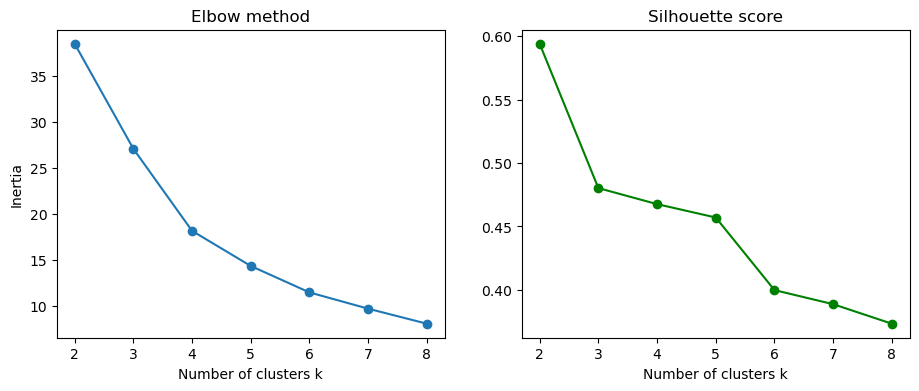

 k  inertia  silhouette
 2     38.5       0.594
 3     27.0       0.480
 4     18.1       0.468
 5     14.3       0.457
 6     11.4       0.400
 7      9.7       0.389
 8      8.0       0.373


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouettes = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(2, 9), inertias, marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia")

axes[1].plot(range(2, 9), silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
plt.show()

print(pd.DataFrame({"k": range(2, 9), "inertia": np.round(inertias, 1), "silhouette": np.round(silhouettes, 3)}).to_string(index=False))

**What to say:** *The silhouette score is highest for k = 2, but two groups (stressed and not stressed) is too coarse to be useful. The elbow bends around k = 3, and the silhouette is still reasonable there. So I chose k = 3: low, medium and high stress.*

## Step 6: The random initialisation trap
**What to say:** *K-Means starts from random centres, and a bad start can trap it in a poor solution. To show this, I run it 10 times with purely random starts (one try each) and compare the inertia. The standard fix is k-means++ (smarter starting centres) combined with several tries, keeping the best result. This is what scikit-learn does by default.*

In [6]:
random_runs = []
for seed in range(10):
    km = KMeans(n_clusters=3, init="random", n_init=1, random_state=seed).fit(X)
    random_runs.append(km.inertia_)

print("Inertia with random starts (10 runs):", np.round(random_runs, 2))
print("Worst:", round(max(random_runs), 2), "| Best:", round(min(random_runs), 2))

good = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X)
print("Inertia with k-means++ and 10 tries:", round(good.inertia_, 2))

Inertia with random starts (10 runs): [28.45 27.06 28.45 27.04 28.45 27.04 28.45 27.04 28.45 27.28]
Worst: 28.45 | Best: 27.04
Inertia with k-means++ and 10 tries: 27.04


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

**What to say:** *Some random starts end up with a worse (higher) inertia than the best one. k-means++ with several tries reliably finds the best solution.*

## Step 7: Final K-Means clustering (k = 3)
**What to say:** *I name each cluster by its average percentage of at-risk wells: the lowest becomes Low stress, the middle Medium stress and the highest High stress.*

In [7]:
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
districts["cluster"] = kmeans.fit_predict(X)

# name the clusters from lowest to highest average % at risk
rank = districts.groupby("cluster")["pct_at_risk"].mean().sort_values().index.tolist()
names = {rank[0]: "Low stress", rank[1]: "Medium stress", rank[2]: "High stress"}
districts["cluster_name"] = districts["cluster"].map(names)

profile = districts.groupby("cluster_name")[["wells", "avg_depth_2022", "avg_change", "avg_recharge", "pct_at_risk", "pct_dry"]].mean().round(1)
profile["districts"] = districts["cluster_name"].value_counts()
profile.loc[["Low stress", "Medium stress", "High stress"]]

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,wells,avg_depth_2022,avg_change,avg_recharge,pct_at_risk,pct_dry,districts
cluster_name,,,,,,,
Low stress,56.5,9.9,-0.8,4.7,6.9,0.1,15
Medium stress,50.9,26.8,4.1,0.0,52.6,0.5,10
High stress,61.5,58.3,3.9,1.1,85.5,2.8,8


In [8]:
for name in ["Low stress", "Medium stress", "High stress"]:
    members = districts[districts["cluster_name"] == name].sort_values("pct_at_risk")
    print(name + " (" + str(len(members)) + " districts):")
    print("   " + ", ".join(members["label"]))
    print()

Low stress (15 districts):
   Ahmednagar (M), Buldhana (M), Jalna (M), Nagpur (M), Nashik (M), Osmanabad (M), Pune (M), Sangli (M), Solapur (M), Latur (M), Satara (M), Amravati (M), Yamunanagar (H), Jalgaon (M), Sabarkantha (G)

Medium stress (10 districts):
   Palwal (H), Karnal (H), Faridabad (H), Bhiwani (H), Kachchh (G), Kaithal (H), Fatehabad (H), Panipat (H), Sirsa (H), Gurugram (H)

High stress (8 districts):
   Mahesana (G), Patan (G), Banaskantha (G), Mahendragarh (H), Rewari (H), Gandhinagar (G), Kurukshetra (H), Charki Dadri (H)



**What to say:** *The three clusters make sense. Low-stress districts have shallow water, almost no at-risk wells and a good recovery after the monsoon. High-stress districts have the deepest water and the largest share of at-risk wells. Both the Medium and High groups are getting deeper over the years (positive average change), while Low-stress districts are stable. (H = Haryana, G = Gujarat, M = Maharashtra.)*

## Step 8: Visualise the clusters
**What to say:** *Each dot is a district. The further right and higher, the deeper the water and the larger the share of at-risk wells.*

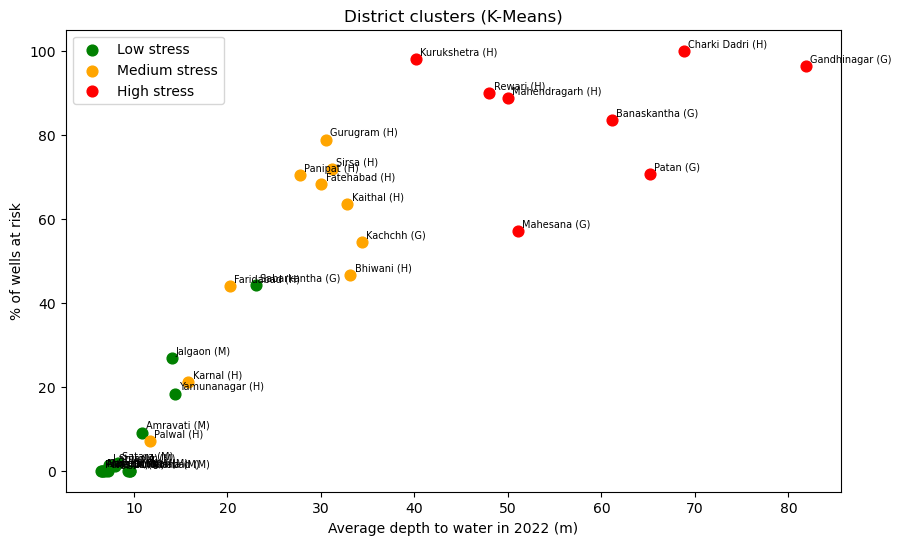

In [9]:
colors = {"Low stress": "green", "Medium stress": "orange", "High stress": "red"}

plt.figure(figsize=(10, 6))
for name, color in colors.items():
    part = districts[districts["cluster_name"] == name]
    plt.scatter(part["avg_depth_2022"], part["pct_at_risk"], c=color, label=name, s=60)
    for _, row in part.iterrows():
        plt.annotate(row["label"], (row["avg_depth_2022"], row["pct_at_risk"]), fontsize=7, xytext=(3, 3), textcoords="offset points")

plt.xlabel("Average depth to water in 2022 (m)")
plt.ylabel("% of wells at risk")
plt.title("District clusters (K-Means)")
plt.legend()
plt.show()

## Step 9: Hierarchical (agglomerative) clustering
**What to say:** *Hierarchical clustering starts with every district alone, then repeatedly merges the two closest groups until only one is left. The result is a tree called a dendrogram. How 'closest' is measured is called the linkage:*

- **Single:** distance between the two nearest members of the groups
- **Complete:** distance between the two farthest members
- **Average:** average distance between all pairs of members
- **Centroid:** distance between the centres of the groups

*The cophenetic correlation tells how faithfully a dendrogram keeps the original distances (closer to 1 is better).*

In [10]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

linkages = {}
cophenetic_scores = {}
for method in ["single", "complete", "average", "centroid"]:
    Z = linkage(X, method=method)
    linkages[method] = Z
    cophenetic_scores[method], _ = cophenet(Z, pdist(X))

print("Cophenetic correlation:")
for method, score in cophenetic_scores.items():
    print("  ", method, round(score, 3))

Cophenetic correlation:
   single 0.773
   complete 0.871
   average 0.874
   centroid 0.873


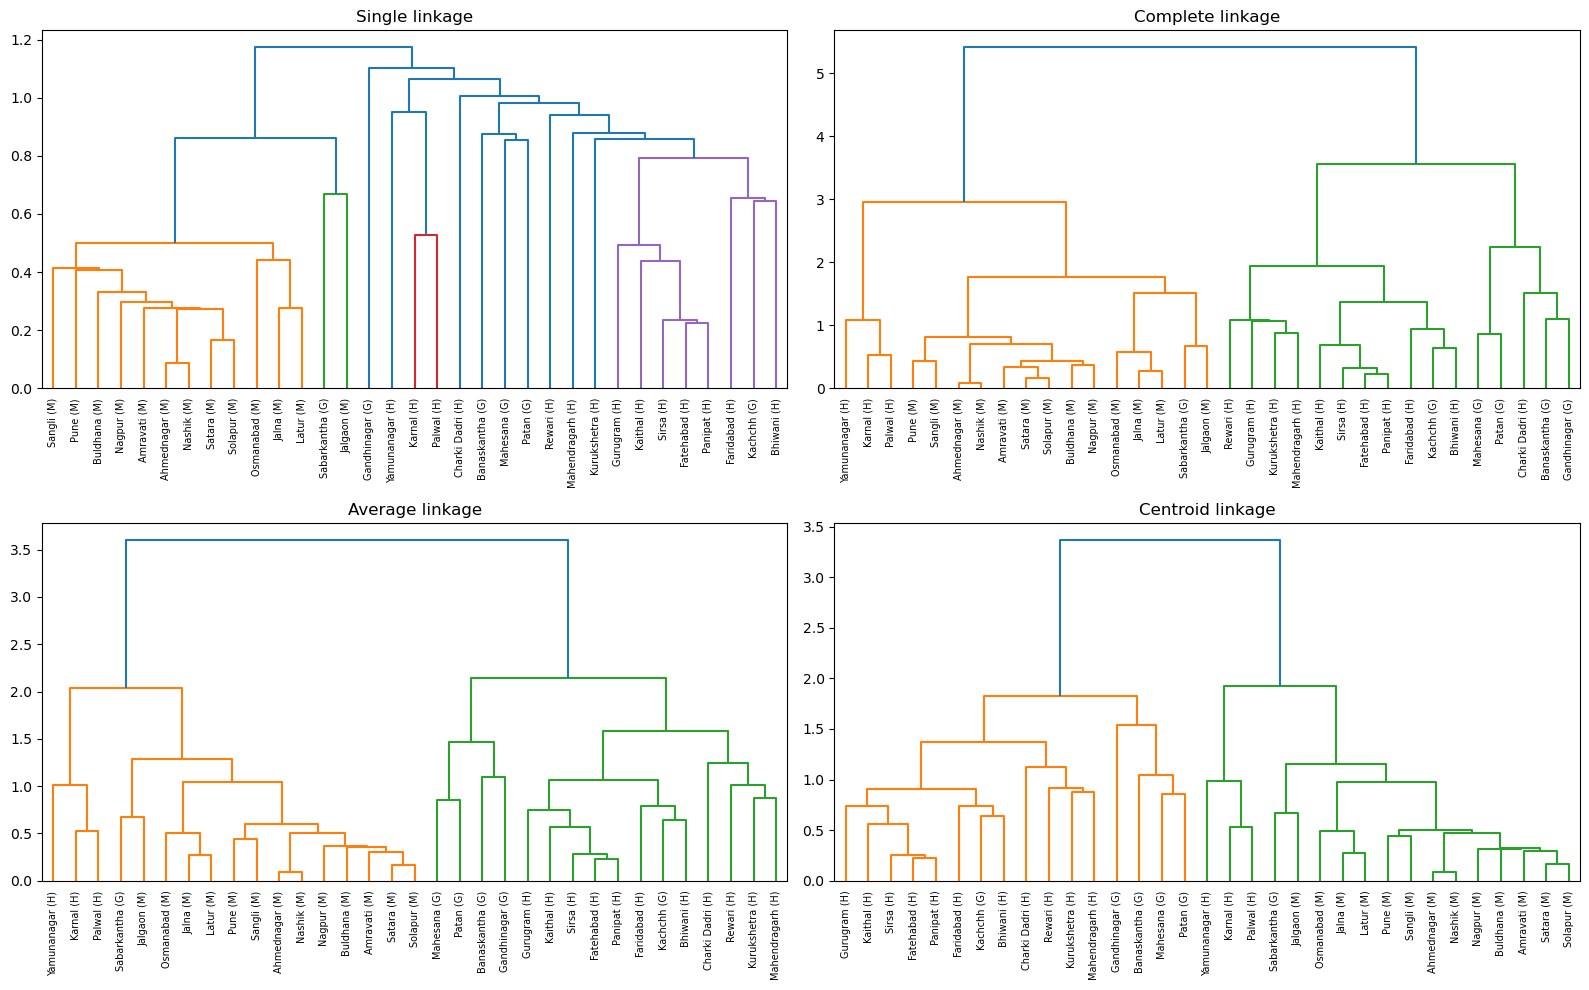

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, method in zip(axes.flatten(), linkages):
    dendrogram(linkages[method], labels=districts["label"].tolist(), leaf_font_size=7, ax=ax)
    ax.set_title(method.capitalize() + " linkage")
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

**What to say:** *Single linkage tends to build long chains and is the hardest to read. Complete and average give more balanced groups. I use the linkage with the highest cophenetic correlation.*

## Step 10: Cut the dendrogram into 3 clusters and compare with K-Means
**What to say:** *Cutting the tree so that 3 groups remain gives the hierarchical clusters. I then check how closely they agree with K-Means.*

In [12]:
best_linkage = max(cophenetic_scores, key=cophenetic_scores.get)
print("Linkage used:", best_linkage)

districts["hier_cluster"] = fcluster(linkages[best_linkage], t=3, criterion="maxclust")

# name the hierarchical clusters the same way (by % at risk)
rank_h = districts.groupby("hier_cluster")["pct_at_risk"].mean().sort_values().index.tolist()
names_h = {rank_h[0]: "Low stress", rank_h[1]: "Medium stress", rank_h[2]: "High stress"}
districts["hier_name"] = districts["hier_cluster"].map(names_h)

print()
print("Rows = K-Means, columns = Hierarchical")
print(pd.crosstab(districts["cluster_name"], districts["hier_name"]))

Linkage used: average

Rows = K-Means, columns = Hierarchical
hier_name      High stress  Low stress  Medium stress
cluster_name                                         
High stress              4           0              4
Low stress               0          15              0
Medium stress            0           2              8


In [13]:
from sklearn.metrics import adjusted_rand_score

print("Adjusted Rand index (1 = identical groups):", round(adjusted_rand_score(districts["cluster"], districts["hier_cluster"]), 3))

Adjusted Rand index (1 = identical groups): 0.618


## Step 11: Save the results
**What to say:** *I saved the district table with both cluster labels. It can be used for the final conclusions.*

In [14]:
districts.round(2).to_csv("07_district_clusters.csv", index=False)
print("Saved 07_district_clusters.csv")
print(districts["cluster_name"].value_counts())

Saved 07_district_clusters.csv
cluster_name
Low stress       15
Medium stress    10
High stress       8
Name: count, dtype: int64


## Conclusion
**What to say:** *Clustering found three groups of districts that make sense without using any labels: low, medium and high groundwater stress. Both K-Means and hierarchical clustering agree on most districts. Districts in the high-stress group are the ones that need attention first. One limit: a few districts have few wells (Rewari has only 10), so their numbers are less reliable.*

---
**Next: the extra notebook** covering Units V and VI: PCA, neural network (MLP), bagging and boosting, Random Forest, bias-variance, the final model comparison and the list of priority districts.